# Tap-test localization of the DAS channels

Where along the cable is each DAS channel? During the deployment a hammer was
struck on the ice next to the cable at GPS-logged points. The channel nearest a
tap hears it first, so the first-arrival channel ties a channel number to a GPS
position. With those ties the channels are numbered along the cable route that
was manually traced in the KML.

1. **Candidates**: for every tap, a waterfall of the flexural-gravity packet with
   candidate first-arrival channels (cross-correlation lag minima, amplitude peaks).
2. **Review**: a person chooses the arrival channel from each waterfall.
3. **Geometry**: the reviewed channels register the channel numbering onto the
   walked route; every channel is placed on that route.

In [ ]:
from IPython.display import Image, display

from das_tools import maps
from das_tools import tap_localization as tl
from das_tools.processing import pisces25
from das_tools.utils import proj_path

PICKS = proj_path.data_dir("tapTestLoc_picks.csv")
KML = proj_path.data_dir("CableRoute2025_onice_traced_smoothed.kml")
BEND_CSV = proj_path.data_dir("bend_change_shortest.csv")
DAS_GLOB = str(proj_path.hammer_das_dir("decimator*.h5"))

OUT_DIR = proj_path.output_dir("tap_localization")
REVIEW_DIR = OUT_DIR / "review"
GEOMETRY_NAME = "channel_geometry_20260908"

# Canonical numbering: the cable bend is channel 594, as in the first
# recordings of 2025-04-23. shift = 594 - (bend channel of the epoch).
REFERENCE_BEND_CHANNEL = 594
EPOCH_SHIFT_RULES = tl.epoch_shift_rules_from_bend_csv(
    BEND_CSV, reference_bend_channel=REFERENCE_BEND_CHANNEL)
for t0, shift in EPOCH_SHIFT_RULES:
    print(f"from {t0}: canonical = recorded {shift:+d}")

from 2025-04-23T18:32:01+00:00: canonical = recorded +0
from 2025-04-23T23:21:01+00:00: canonical = recorded +8
from 2025-04-24T20:25:00+00:00: canonical = recorded -8
from 2025-04-26T17:05:00+00:00: canonical = recorded +20
from 2025-04-28T07:45:00+00:00: canonical = recorded -8
from 2025-04-30T07:11:00+00:00: canonical = recorded +7
from 2025-05-02T03:23:00+00:00: canonical = recorded +8
from 2025-05-03T06:32:00+00:00: canonical = recorded -8
from 2025-05-04T12:29:00+00:00: canonical = recorded +6
from 2025-05-04T13:02:00+00:00: canonical = recorded -2
from 2025-05-04T19:51:00+00:00: canonical = recorded +10


## 1. Candidate waterfalls

Each tap is reviewed over its own `t1FG..t2FG` window and `f1FG..f2FG` band, on
the channels between `d1` and `d2` (padded by 6 channels, never below
channel 100). The candidates are suggestions only: the protected global minima of
the raw and smoothed relative-arrival curves, its other local minima, and peaks in
packet strength.

In [2]:
cfg = tl.PickConfig(data_glob=DAS_GLOB, channel_epoch_shift_rules=EPOCH_SHIFT_RULES)
candidate_rows = tl.generate_review_candidates(PICKS, cfg, REVIEW_DIR)

 1: 2025-04-23T23:49:00.000000: no raw record on disk; kept pick 108.0
 2: 2025-04-23T23:52:00.000000: no raw record on disk; kept pick 128.0
 3: 2025-04-23T23:54:00.000000: no raw record on disk; kept pick 137.0
 4: 2025-04-23T23:59:00.000000: no raw record on disk; kept pick 183.0
 5: 2025-04-24T00:09:00.000000: no raw record on disk; kept pick 240.0
 6: 2025-04-24T00:12:00.000000: no raw record on disk; kept pick 300.0
 7: 2025-04-24T00:15:00.000000: no raw record on disk; kept pick 382.0


 8: 2025-04-24T00:25:10.274900: review 464:646; candidates [467, 480, 498, 527, 572, 584, 587, 592, 622, 639]


 9: 2025-04-24T00:27:36.894900: review 479:646; candidates [511, 569, 576, 609, 613, 617]


10: 2025-04-24T00:30:26.576900: review 464:646; candidates [491, 502, 537, 560, 572, 590, 600, 638, 642]


11: 2025-04-24T21:55:00.000000: review 464:571; candidates [468, 496, 507, 515]


12: 2025-04-24T22:47:27.000000: review 464:649; candidates [484, 521, 531, 545, 554, 609, 622, 633]


13: 2025-04-24T22:53:00.000000: review 464:649; candidates [468, 481, 497, 507, 524, 559, 575, 607]


An example. Top: the band-passed strain, each trace scaled to its own
amplitude, time increasing downward. The packet arrives first, at the apex of
the moveout, on the channel nearest the hammer. Middle: packet strength per
channel. Bottom: arrival time relative to the earliest channel, from the
cross-correlation lag graph; its minimum is the automatic suggestion.

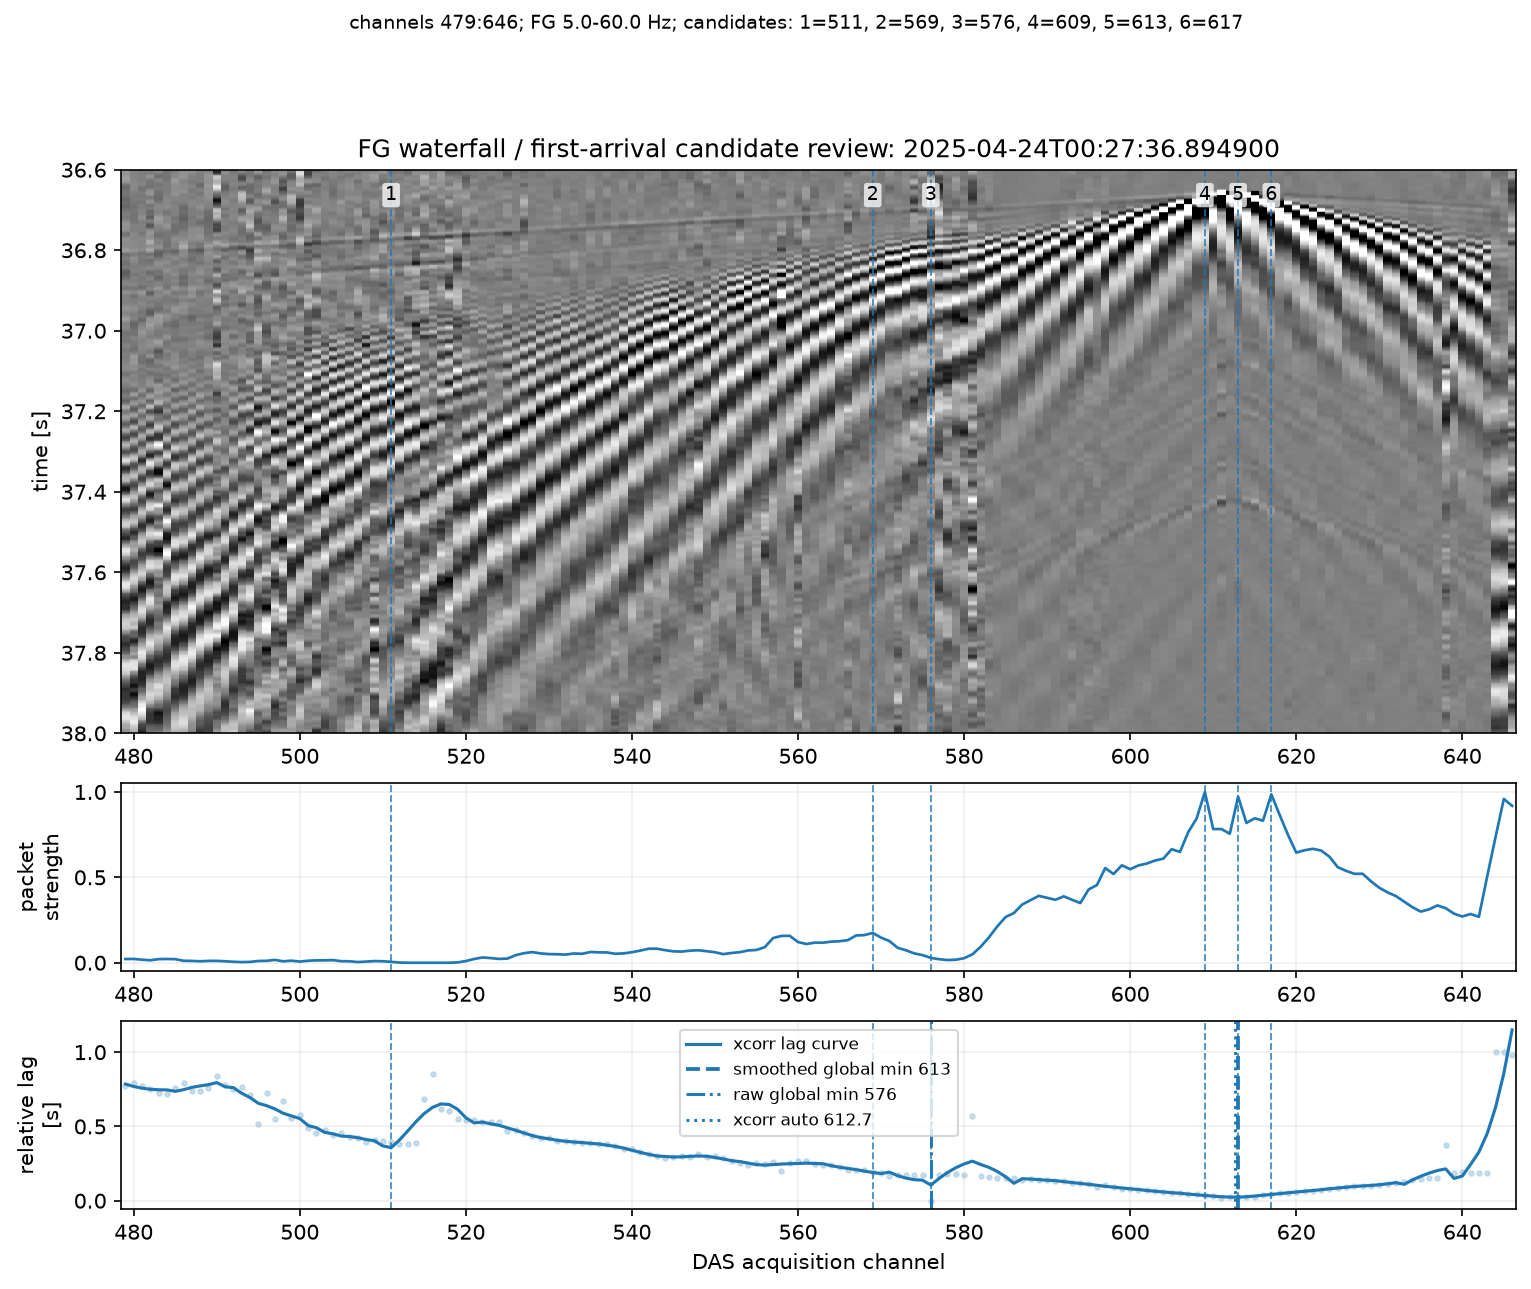

In [3]:
example = next(r for r in candidate_rows if r["timestamp"].startswith("2025-04-24T00:27"))
display(Image(filename=example["candidate_plot"], width=900))

## 2. Review

`review_candidates_interactive` shows each waterfall and asks for the arrival
channel: a candidate number, a recorded channel inside the review aperture,
`c<channel>` to force a channel, `#<n>` to force candidate *n*, `s` to leave
the tap unpicked, `q` to save and stop. Progress is saved after every tap.

Taps that already have an `arrival_channel` in `tapTestLoc_picks.csv` are
skipped, so with `REDO = False` this cell only copies the reviewed picks into
`review/candidates_reviewed.csv`. Set `REDO = True` to go through every tap with
a waterfall again (Enter keeps the current pick). To make a new review the
reference, copy its `arrival_channel` column back into
`data/tapTestLoc_picks.csv`.

In [4]:
REDO = False
reviewed_rows = tl.review_candidates_interactive(
    REVIEW_DIR / "candidates.csv", REVIEW_DIR / "candidates_reviewed.csv", redo=REDO)

## 3. Channel geometry on the walked route

Each reviewed tap gives one knot: its canonical channel and the along-route
distance of the route point nearest its GPS fix. Between knots the channels are
spaced evenly along the route; before the first and after the last knot they
continue at the nominal 3.19 m spacing, along the route while it lasts and then
straight along its end direction. Every channel therefore lies on the walked
route. The hammers decide only where along it each channel sits. The distance
from each hammer to the route (`cross_track_m`) is reported, not fitted.

`_L.npz` holds the channels the hourly decimated files keep: the bend channel
± the short-leg half width of `bend_change_shortest.csv`.

In [5]:
anchors = tl.load_reviewed_anchors(REVIEW_DIR / "candidates_reviewed.csv", EPOCH_SHIFT_RULES)
route = maps.load_kml_route(KML)
geom = tl.build_route_channel_map(
    anchors, route, tl.RouteMapConfig(channel_epoch_shift_rules=EPOCH_SHIFT_RULES))

_, leg_half_width = pisces25.load_bend_schedule(BEND_CSV)
summary = tl.save_channel_geometry(
    geom, OUT_DIR, name=GEOMETRY_NAME,
    bend_channel=REFERENCE_BEND_CHANNEL, leg_half_width=leg_half_width)

print(f"walked route {summary['route_length_m']:.1f} m; {summary['n_channels']} channels, "
      f"{summary['n_channels_on_route']} on the walked route")
print(f"cable length {summary['total_cable_length_m']:.1f} m "
      f"(nominal {summary['nominal_cable_length_m']:.1f} m)")
print(f"hammer to assigned channel: median {summary['hammer_assignment_error_median_m']:.2f} m, "
      f"max {summary['hammer_assignment_error_max_m']:.2f} m")
print(f"written to {OUT_DIR}")

walked route 1802.5 m; 655 channels, 567 on the walked route
cable length 2078.8 m (nominal 2086.6 m)
hammer to assigned channel: median 3.88 m, max 7.72 m
written to /Users/junsuj/Desktop/git/das-landfast-ice-inversion2025/outputs/tap_localization


Figures S1 (`figures/supplementary/S1_tap_location`) and S2
(`figures/supplementary/S2_channel_spacing`) are drawn from these outputs.